# 02 — Off-Plan vs Ready ("Developer Premium") Analysis

Estimates the observational price differential between off-plan and ready sales using:
1. **Area × Quarter Fixed Effects** (controlling for unit area, type, and bedrooms)
2. **Project × Quarter Fixed Effects** (absorbs building prestige where both off-plan & ready sales exist)
3. **Exact Cell Matching** and **Time-to-Catch-Up** cohort analysis.

> **Caveat**: Estimates capture observational price associations, not causal markups. Payment plans, finish upgrades, and floor/view mix are unobserved.

In [1]:
import json
import os
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from dfv.config import PATHS, get_data_mode

mode = get_data_mode()
data_dir = PATHS.processed if mode == "processed" else PATHS.sample
print(f"Active data mode: {mode} | Directory: {data_dir}")

from dfv.analysis.developer_premium import analyze_developer_premium

Active data mode: sample | Directory: /Users/shahinhamza/.gemini/antigravity/scratch/dubai-fair-value/data/sample


In [2]:
analysis_json = data_dir / "analysis" / "developer_premium.json"
if analysis_json.exists():
    dev_res = json.loads(analysis_json.read_text(encoding="utf-8"))
else:
    feat = pd.read_parquet(data_dir / "features.parquet")
    dev_res = analyze_developer_premium(feat, min_group_obs=10)

print("Caveat:", dev_res["caveat"])
print(f"Unknown developer share: {dev_res['unknown_developer_pct']}%")
print("Overall Area x Quarter FE:", dev_res["overall_area_quarter_fe"])
print("Overall Project x Quarter FE:", dev_res["overall_project_quarter_fe"])
print("Matched comparison:", dev_res["matched_comparison"])

Caveat: Observational association only; does not adjust for unobserved post-handover payment plans, launch incentives, view/floor tiers, or snagging risk. Named developers with thin samples (<8 off-plan & ready sales each) are excluded.
Unknown developer share: 0.0%
Overall Area x Quarter FE: {'term': 'is_offplan', 'log_coef': 0.06569, 'se_robust': 0.00353, 'pct_effect': 6.79, 'ci_low_pct': 6.05, 'ci_high_pct': 7.53, 'p_value': 0.0, 'n_obs': 4959, 'r2_within': 0.1395}
Overall Project x Quarter FE: {'term': 'is_offplan', 'log_coef': 0.0563, 'se_robust': 0.00536, 'pct_effect': 5.79, 'ci_low_pct': 4.69, 'ci_high_pct': 6.91, 'p_value': 0.0, 'n_obs': 3984, 'r2_within': 0.1469}
Matched comparison: {'matched_cells': 85, 'matched_pct_premium': 8.45, 'ci_low_pct': 6.68, 'ci_high_pct': 10.24}


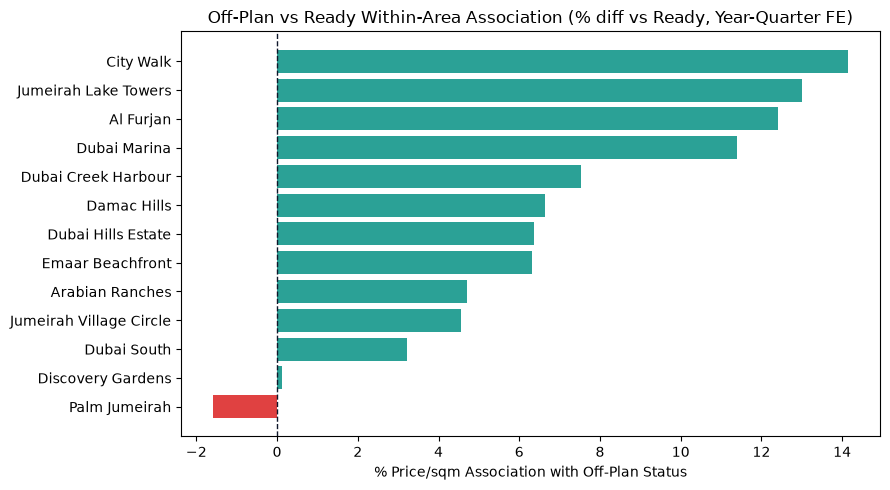

In [3]:
by_area = pd.DataFrame(dev_res["by_area"])
if not by_area.empty:
    top_bot = pd.concat([by_area.head(8), by_area.tail(5)]).drop_duplicates("area_name")
    top_bot = top_bot.sort_values("pct_premium")
    fig, ax = plt.subplots(figsize=(9, 5))
    colors = ["#DC2626" if v < 0 else "#0D9488" for v in top_bot["pct_premium"]]
    ax.barh(top_bot["area_name"], top_bot["pct_premium"], color=colors, alpha=0.88)
    ax.axvline(0.0, color="#0F172A", linestyle="--", linewidth=1.0)
    ax.set_title("Off-Plan vs Ready Within-Area Association (% diff vs Ready, Year-Quarter FE)")
    ax.set_xlabel("% Price/sqm Association with Off-Plan Status")
    plt.tight_layout()
    plt.show()

In [4]:
catchup = pd.DataFrame(dev_res["time_to_catch_up"])
print(f"Areas evaluated for catch-up: {len(catchup)}")
catchup.head(12)

Areas evaluated for catch-up: 12


,area_name,evaluated_cohorts,cohorts_caught_up,median_catchup_months,status
0,Jumeirah Village Circle,42,39,15.0,Observed forward catch-up
1,Downtown Dubai,19,19,21.0,Observed forward catch-up
2,Dubai Creek Harbour,14,13,21.0,Observed forward catch-up
3,Business Bay,31,31,27.0,Observed forward catch-up
4,Damac Hills,3,2,27.0,Observed forward catch-up
5,Dubai Marina,28,28,30.1,Observed forward catch-up
6,Discovery Gardens,4,3,36.0,Observed forward catch-up
7,Palm Jumeirah,10,10,36.0,Observed forward catch-up
8,Al Furjan,17,17,42.0,Observed forward catch-up
9,Dubai Hills Estate,16,16,52.5,Observed forward catch-up
